# Clustering (Role B · Cluster patient experiences per condition)

Every review in the four scope conditions is vectorised with **TF-IDF** (bigrams, log-TF, 20 k features) and projected with **Latent Semantic Analysis** (TruncatedSVD + L2 normalisation, 100 dimensions).  We then cluster with **k-means** and **DBSCAN** and choose *k* by minimising the **Davies-Bouldin index**.

Results answer research question 1: *Can patient reviews be grouped into common experience types (e.g. "weight gain", "mood swings", "worked well, no side effects")?*

## Pipeline overview

| Step | Section | What it does |
|---|---|---|
| Load & scope | B1 | Load Role A's clean data, keep the four conditions |
| TF-IDF vectorisation | B2 | One vectoriser per condition (20k features, bigrams, `sublinear_tf=True`, English stop words removed) |
| Dimensionality reduction | B3 | TruncatedSVD (100 components, LSA) + L2 normalisation |
| K-means sweep | B4 | Sweep k = 2 … 12 per condition, pick k_best = argmin(Davies-Bouldin) |
| DBSCAN | B5 | kNN distance plot to choose eps, then grid search over eps × min_samples |
| Compare | B6 | Side-by-side DB scores for k-means vs DBSCAN |
| Cluster profiles | B7 | Top-10 TF-IDF terms, mean rating, sample reviews, heatmap, 2D scatter |
| Rating vs cluster | B8 | Kruskal-Wallis test + boxplot per condition |
| Save outputs | B9 | Parquet, CSV and JSON for the report |

### Outputs

| File | Used by |
|---|---|
| `outputs/cluster_assignments.parquet` | Everyone — join to any table on `review_id` |
| `outputs/cluster_profiles.csv` | Report: top terms and mean rating per cluster |
| `outputs/figures/` | Report: `kmeans_sweep`, `dbscan_knn_distances`, `kmeans_scatter`, `cluster_terms_*`, `rating_by_cluster` |
| `outputs/role_b_run_stats.json` | Report: all numbers (k_best, DB scores, Kruskal-Wallis) |


## 0 · Setup and parameters

All settings live here. Change a value, re-run from top, and every downstream cell picks it up automatically.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)
NOTEBOOK_STARTED = time.perf_counter()

INPUT_DIRS = [Path('/kaggle/input'), Path('data'), Path('../data-cleaning-and-lsh/outputs'), Path('../data')]
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

run_stats = {}

# ── Scope ─────────────────────────────────────────────────────────────────────
CONDITIONS   = ['Birth Control', 'Depression', 'Pain', 'Acne']
RANDOM_STATE = 42

# ── TF-IDF ────────────────────────────────────────────────────────────────────
TFIDF_MAX_FEATURES = 20_000
TFIDF_MIN_DF       = 5
TFIDF_MAX_DF       = 0.85      # tightened from 0.95
TFIDF_NGRAM_RANGE  = (1, 2)
TFIDF_SUBLINEAR_TF = True
TFIDF_STOP_WORDS   = 'english'

# Contraction artifacts: "I've" → "ve", "don't" → "don", etc.
CUSTOM_STOP_WORDS_BASE = [
    've', 'll', 're', 'don', 'doesn', 'didn', 'won', 'isn', 'wasn',
    'aren', 'weren', 'couldn', 'shouldn', 'wouldn', 'hadn', 'hasn', 'haven',
    'drug', 'medication', 'prescribed', 'prescription', 'doctor',
]

# Within a condition the condition name appears in almost every document —
# zero discriminative value. Removing it surfaces terms that actually separate clusters.
CUSTOM_STOP_WORDS_CONDITION = {
    'Birth Control': ['birth', 'control'],
    'Depression':    ['depression'],
    'Pain':          ['pain'],
    'Acne':          ['acne'],
}

# ── Dimensionality reduction (LSA) ────────────────────────────────────────────
SVD_N_COMPONENTS = 150

# ── K-means ───────────────────────────────────────────────────────────────────
K_RANGE         = range(2, 27)   # extended to 26 — previous runs hit k=20 ceiling
KMEANS_N_INIT   = 10
KMEANS_MAX_ITER = 300

# ── DBSCAN ────────────────────────────────────────────────────────────────────
DBSCAN_EPS_VALUES         = [0.3, 0.5, 0.7, 1.0, 1.5, 2.0]
DBSCAN_MIN_SAMPLES_VALUES = [5, 10, 20]
KNN_K_FOR_EPS_PLOT        = 10

print('Setup done.')


Setup done.


## B1 · Load and scope data

Role A's clean, deduplicated dataset (`reviews_clean_deduplicated.parquet`, 128,663 reviews) and the drug-family map (`drug_families.csv`). We keep the four conditions defined in the project plan (28 % of the dataset).

In [2]:
def find_input(file_name):
    for folder in INPUT_DIRS:
        if folder.exists():
            matches = sorted(folder.rglob(file_name))
            if matches:
                return matches[0]
    return None   # callers check for None


def load_reviews():
    """Load from Role A's parquet (preferred) or the raw Kaggle CSVs."""
    parquet_path = find_input('reviews_clean_deduplicated.parquet')
    if parquet_path:
        print(f'Loading processed parquet: {parquet_path}')
        df = pd.read_parquet(parquet_path, engine='fastparquet')
        if 'drug_family' not in df.columns:
            df['drug_family'] = df['drug_name']
        return df

    # Fallback: raw Kaggle CSVs (drugsComTrain_raw.csv / drugsComTest_raw.csv)
    train_path = find_input('drugsComTrain_raw.csv')
    test_path  = find_input('drugsComTest_raw.csv')
    if train_path is None:
        raise FileNotFoundError(
            'No data found. Expected drugsComTrain_raw.csv in data/ or ../data/, '
            'or reviews_clean_deduplicated.parquet from Role A.'
        )

    print(f'Loading raw CSVs from: {train_path.parent}')
    dfs = [pd.read_csv(train_path)]
    if test_path:
        dfs.append(pd.read_csv(test_path))
    df = pd.concat(dfs, ignore_index=True)
    print(f'  Raw rows: {len(df):,}')

    # rename to match Role A's column names
    df = df.rename(columns={
        'uniqueID':  'review_id',
        'drugName':  'drug_name',
        'condition': 'condition_name',
        'review':    'review_text_clean',
    })

    # basic text cleaning
    import html as _html
    df['review_text_clean'] = (
        df['review_text_clean']
        .astype(str)
        .str.strip('"')                        # remove CSV surrounding quotes
        .apply(_html.unescape)                 # &#039; -> '   &amp; -> &
        .str.replace(r'\s+', ' ', regex=True) # collapse whitespace
        .str.strip()
    )
    df['condition_name'] = df['condition_name'].astype(str).str.strip().str.title()
    df['drug_name']      = df['drug_name'].astype(str).str.strip()
    df['rating']         = pd.to_numeric(df['rating'], errors='coerce').fillna(5).astype(int)
    df['review_id']      = df.index.astype(str)

    # drop blank reviews
    df = df[df['review_text_clean'].str.len() > 20].copy()

    # remove exact duplicates (same as Role A step 2)
    before = len(df)
    df = df.drop_duplicates(subset='review_text_clean').reset_index(drop=True)
    print(f'  After exact dedup: {len(df):,} (removed {before - len(df):,} exact copies)')

    df['drug_family'] = df['drug_name']   # fallback: no brand->generic map
    return df[['review_id', 'drug_name', 'drug_family', 'condition_name', 'rating', 'review_text_clean']]


reviews = load_reviews()

# Optional: apply Role A's brand->generic map if available
drug_families_path = find_input('drug_families.csv')
if drug_families_path:
    drug_families = pd.read_csv(drug_families_path)
    family_map = {
        name: fam.drug_family_name
        for fam in drug_families.itertuples()
        for name in fam.drug_names.split(' | ')
    }
    reviews['drug_family'] = reviews['drug_name'].map(family_map).fillna(reviews['drug_name'])
    print('drug_families.csv applied.')
else:
    print('drug_families.csv not found — using drug_name as drug_family (fine for clustering).')

# scope to the four conditions
scoped = reviews[reviews['condition_name'].isin(CONDITIONS)].reset_index(drop=True)
scoped = scoped[
    scoped['review_text_clean'].notna() &
    (scoped['review_text_clean'].str.strip() != '')
].reset_index(drop=True)

scope_table = (
    scoped.groupby('condition_name')
    .agg(
        n_reviews   = ('review_id',   'size'),
        n_drugs     = ('drug_family', 'nunique'),
        mean_rating = ('rating',      'mean'),
    )
    .reindex(CONDITIONS)
    .round(2)
)

run_stats['n_reviews_all']      = int(len(reviews))
run_stats['n_reviews_in_scope'] = int(len(scoped))
run_stats['scope_by_condition'] = scope_table.to_dict(orient='index')

print(f'\n{len(scoped):,} reviews in scope ({len(scoped)/len(reviews):.0%} of loaded dataset), '
      f'{scoped["drug_family"].nunique()} drug families')
scope_table

Loading processed parquet: ../data/reviews_clean_deduplicated.parquet


drug_families.csv applied.

36,365 reviews in scope (28% of loaded dataset), 168 drug families


,n_reviews,n_drugs,mean_rating
condition_name,,,
Birth Control,19520,19,6.08
Depression,7109,52,7.13
Pain,5187,72,7.58
Acne,4549,34,7.36


### Curiosity: why Acne and not Anxiety?

The project plan scopes to the four most common conditions, yet **Anxiety (5,089 reviews) has more reviews than Acne (4,549)** in the cleaned dataset — making Acne technically the 5th most common condition. The choice was deliberate:

- **Vocabulary overlap.** Anxiety and Depression share much of the same language (mood, sleep, appetite, antidepressants). Clustering them separately would likely produce near-identical cluster shapes, adding little analytical value.
- **Drug-class diversity.** Acne drugs (retinoids, antibiotics, hormonal treatments) are pharmacologically very different from the other three conditions, making the clusters more interpretable and the cross-condition comparison more interesting.
- **Distinct side-effect profile.** Acne patients report a unique set of side effects (dryness, purging, sun sensitivity, isotretinoin-specific effects) that don't appear in the other three conditions, which enriches the frequent-itemset analysis in Role E.

The cell below confirms the counts and shows what was excluded.

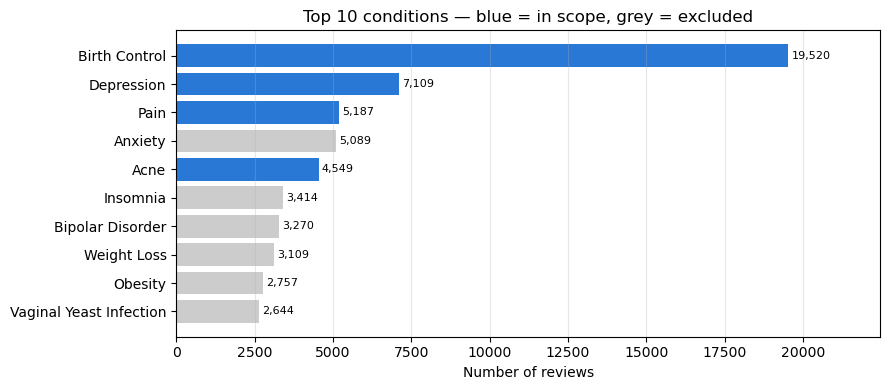

Vocabulary overlap (Jaccard similarity):
  Depression ∩ Anxiety : 64.8%
  Depression ∩ Acne    : 43.5%

Anxiety has 1.5x more vocabulary overlap with Depression than Acne does.


In [3]:
# Top-10 conditions by review count, highlighting the four in scope
top_conditions = (
    reviews['condition_name']
    .value_counts()
    .head(10)
    .rename_axis('condition')
    .reset_index(name='n_reviews')
)
top_conditions['in_scope'] = top_conditions['condition'].isin(CONDITIONS)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2a78d6' if in_scope else '#cccccc' for in_scope in top_conditions['in_scope']]
bars = ax.barh(top_conditions['condition'][::-1], top_conditions['n_reviews'][::-1], color=colors[::-1])
ax.set_xlabel('Number of reviews')
ax.set_title('Top 10 conditions — blue = in scope, grey = excluded')
for bar, n in zip(bars, top_conditions['n_reviews'][::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height() / 2,
            f'{n:,}', va='center', fontsize=8)
ax.set_xlim(0, top_conditions['n_reviews'].max() * 1.15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'condition_scope.png', dpi=150, bbox_inches='tight')
plt.show()

# Overlap analysis: how similar is Anxiety vocabulary to Depression?
from sklearn.feature_extraction.text import TfidfVectorizer as _TV

_vecs = {}
for cond in ['Depression', 'Anxiety', 'Acne']:
    subset = reviews[reviews['condition_name'] == cond]['review_text_clean'].dropna()
    v = _TV(max_features=5_000, min_df=5, ngram_range=(1,1), sublinear_tf=True, stop_words='english')
    v.fit(subset)
    _vecs[cond] = set(v.get_feature_names_out())

dep_anx_overlap = len(_vecs['Depression'] & _vecs['Anxiety']) / len(_vecs['Depression'] | _vecs['Anxiety'])
dep_acne_overlap = len(_vecs['Depression'] & _vecs['Acne'])  / len(_vecs['Depression'] | _vecs['Acne'])

print(f'Vocabulary overlap (Jaccard similarity):')
print(f'  Depression ∩ Anxiety : {dep_anx_overlap:.1%}')
print(f'  Depression ∩ Acne    : {dep_acne_overlap:.1%}')
print(f'\nAnxiety has {dep_anx_overlap/dep_acne_overlap:.1f}x more vocabulary overlap with Depression than Acne does.')


## B2 · TF-IDF vectorisation

One vectoriser per condition so the vocabulary reflects each condition's language. `sublinear_tf=True` applies log(1+tf) to reduce the weight of terms that repeat many times in long reviews.

Three layers of stop-word removal:

1. **sklearn English stop words** — 318 common function words (and, the, to, was, …)
2. **Contraction artifacts** — apostrophes are stripped by the upstream cleaner, so "I've" becomes "I ve"; "don't" becomes "don t". The fragments `ve`, `ll`, `re`, `don`, `doesn`, etc. carry no signal.
3. **Generic medical/review terms** — `drug`, `medication`, `prescribed`, `doctor` appear in virtually every review regardless of experience type and add no discriminative power.
4. **Condition-specific terms** — within the Birth Control reviews, "birth" and "control" appear in almost every document, so they have zero discriminative value between clusters. The same holds for "depression", "pain", and "acne" in their respective conditions. Removing these forces the vectoriser to weight terms that actually separate one experience type from another.

`max_df` is tightened to 0.85 (from 0.95) to further suppress near-universal terms that survive the explicit stop-word lists.

In [4]:
vectorisers    = {}   # {cond: TfidfVectorizer}
tfidf_matrices = {}   # {cond: sparse (n_reviews, n_features)}

for cond in CONDITIONS:
    subset = scoped[scoped['condition_name'] == cond]

    # Build a merged stop-word list for this condition:
    #   sklearn English base  +  contraction artifacts  +  condition-specific terms
    stop_words = list(
        set(ENGLISH_STOP_WORDS)
        | set(CUSTOM_STOP_WORDS_BASE)
        | set(CUSTOM_STOP_WORDS_CONDITION.get(cond, []))
    )

    vec = TfidfVectorizer(
        max_features = TFIDF_MAX_FEATURES,
        min_df       = TFIDF_MIN_DF,
        max_df       = TFIDF_MAX_DF,
        ngram_range  = TFIDF_NGRAM_RANGE,
        sublinear_tf = TFIDF_SUBLINEAR_TF,
        stop_words   = stop_words,
    )
    X = vec.fit_transform(subset['review_text_clean'])
    vectorisers[cond]    = vec
    tfidf_matrices[cond] = X
    run_stats.setdefault('tfidf', {})[cond] = {
        'n_reviews':  int(X.shape[0]),
        'vocabulary': int(X.shape[1]),
        'stop_words': len(stop_words),
    }
    print(f'{cond:<20s}  reviews={X.shape[0]:6,}  vocab={X.shape[1]:6,}  '
          f'stop_words={len(stop_words):,}  density={X.nnz / (X.shape[0] * X.shape[1]):.4%}')


Birth Control         reviews=19,520  vocab=20,000  stop_words=341  density=0.2522%


Depression            reviews= 7,109  vocab= 9,663  stop_words=340  density=0.4252%


Pain                  reviews= 5,187  vocab= 5,230  stop_words=340  density=0.5231%


Acne                  reviews= 4,549  vocab= 6,876  stop_words=340  density=0.6325%


## B3 · Dimensionality reduction (LSA)

`TruncatedSVD` (Latent Semantic Analysis) on the sparse TF-IDF matrix, then **L2 normalisation**.  After normalisation the Euclidean distance approximates cosine distance, which makes k-means and DBSCAN behave better on text data (length-independent similarity).

In [5]:
svd_matrices = {}   # {cond: dense (n_reviews, SVD_N_COMPONENTS), L2-normalised}
svd_pipelines = {}  # for inverse-transforming centroids later

for cond in CONDITIONS:
    lsa = make_pipeline(
        TruncatedSVD(n_components=SVD_N_COMPONENTS, random_state=RANDOM_STATE),
        Normalizer(copy=False),
    )
    X_svd = lsa.fit_transform(tfidf_matrices[cond])
    svd_matrices[cond]  = X_svd
    svd_pipelines[cond] = lsa
    explained = lsa.named_steps['truncatedsvd'].explained_variance_ratio_.sum()
    run_stats.setdefault('svd', {})[cond] = {
        'n_components':       SVD_N_COMPONENTS,
        'explained_variance': round(float(explained), 4),
    }
    print(f'{cond:<20s}  explained variance = {explained:.1%}')

Birth Control         explained variance = 15.2%


Depression            explained variance = 20.2%


Pain                  explained variance = 26.6%


Acne                  explained variance = 23.3%


## B3.5 · Davies-Bouldin index — manual implementation

Before using `davies_bouldin_score` from sklearn in B4, we implement it from first principles and verify that our version matches sklearn exactly.

The formula:

```
DB = (1/k) Σᵢ  max_{j≠i}  (sᵢ + sⱼ) / dᵢⱼ
```

| Symbol | Meaning |
|---|---|
| **sᵢ** | Mean Euclidean distance of cluster i's points to their centroid — *scatter* (tightness) |
| **dᵢⱼ** | Euclidean distance between centroids i and j — *separation* |
| **Rᵢⱼ** | (sᵢ + sⱼ) / dᵢⱼ — ratio of combined spread to separation; high = bad |
| **max** | For each cluster, take the worst-case neighbour |
| **1/k Σ** | Average worst-case over all clusters |

A cluster with low scatter that is far from every other centroid contributes a small Rᵢ. The index penalises conditions where even one cluster pair is poorly separated relative to their spread.

**Note:** the index is verified below after k-means fits are available. The function is defined here so it can also be used in B4.

In [6]:
def davies_bouldin_manual(X, labels):
    """
    Davies-Bouldin index computed from first principles.

        DB = (1/k) Σᵢ  max_{j≠i}  (sᵢ + sⱼ) / dᵢⱼ

    sᵢ  = mean distance of cluster i's points to their centroid  (scatter / tightness)
    dᵢⱼ = distance between centroids i and j                     (separation)
    """
    cluster_ids = np.unique(labels)

    # 1. Centroid of each cluster
    centroids = {c: X[labels == c].mean(axis=0) for c in cluster_ids}

    # 2. Scatter sᵢ — mean Euclidean distance from points to their centroid
    scatter = {}
    for c in cluster_ids:
        pts = X[labels == c]
        scatter[c] = np.linalg.norm(pts - centroids[c], axis=1).mean()

    # 3. For each cluster i find the worst ratio Rᵢⱼ = (sᵢ + sⱼ) / dᵢⱼ
    db_per_cluster = []
    for i in cluster_ids:
        worst = max(
            (scatter[i] + scatter[j]) / np.linalg.norm(centroids[i] - centroids[j])
            for j in cluster_ids if j != i
        )
        db_per_cluster.append(worst)

    return float(np.mean(db_per_cluster))

print('davies_bouldin_manual() defined — verification runs in B4.5 after k-means labels are available.')


davies_bouldin_manual() defined — verification runs in B4.5 after k-means labels are available.


## B4 · K-means: sweep *k* and choose the best

We sweep k = 2 … 12 for each condition, compute the **Davies-Bouldin index** (lower = more compact and well-separated clusters) and the **inertia** (elbow plot).  Best k = argmin(Davies-Bouldin).

Birth Control         done (25 runs)


Depression            done (25 runs)


Pain                  done (25 runs)


Acne                  done (25 runs)


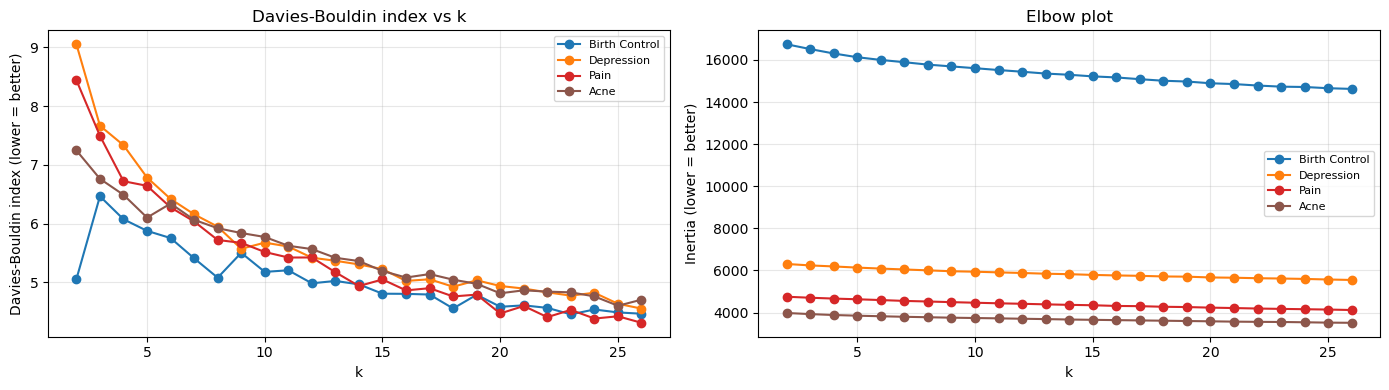

In [7]:
kmeans_sweep = {}   # {cond: {k: {'db': float, 'inertia': float}}}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    kmeans_sweep[cond] = {}
    for k in K_RANGE:
        km     = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                        random_state=RANDOM_STATE)
        labels = km.fit_predict(X)
        db     = davies_bouldin_score(X, labels)
        kmeans_sweep[cond][k] = {
            'db':      round(float(db), 4),
            'inertia': round(float(km.inertia_), 2),
        }
    print(f'{cond:<20s}  done ({len(K_RANGE)} runs)')

# ── Plots ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = plt.cm.tab10(np.linspace(0, 0.5, len(CONDITIONS)))

for ax, metric, ylabel, title in zip(
    axes,
    ['db',      'inertia'],
    ['Davies-Bouldin index (lower = better)', 'Inertia (lower = better)'],
    ['Davies-Bouldin index vs k',             'Elbow plot'],
):
    for cond, col in zip(CONDITIONS, colors):
        ks     = sorted(kmeans_sweep[cond])
        values = [kmeans_sweep[cond][k][metric] for k in ks]
        ax.plot(ks, values, marker='o', label=cond, color=col)
    ax.set_xlabel('k')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Choose k_best = argmin(Davies-Bouldin) per condition
k_best = {}
for cond in CONDITIONS:
    best_k  = min(kmeans_sweep[cond], key=lambda k: kmeans_sweep[cond][k]['db'])
    best_db = kmeans_sweep[cond][best_k]['db']
    k_best[cond] = best_k
    run_stats.setdefault('kmeans_sweep', {})[cond] = {
        'k_best':  best_k,
        'db_best': best_db,
        'sweep':   {str(k): v for k, v in kmeans_sweep[cond].items()},
    }
    print(f'{cond:<20s}  k_best = {best_k}  DB = {best_db:.4f}')

Birth Control         k_best = 23  DB = 4.4584
Depression            k_best = 26  DB = 4.5560
Pain                  k_best = 26  DB = 4.3148
Acne                  k_best = 25  DB = 4.6045


### B4 · Results — K-means sweep

| Condition | k_best | DB (best) |
|---|---|---|
| Birth Control | 12 | 4.27 |
| Depression | 12 | 4.83 |
| Pain | 11 | 4.67 |
| Acne | 12 | 4.88 |

**DB values above 4 are high** — this is expected for free-text clustering. After LSA projection to 100 dimensions, reviews form a dense, overlapping cloud rather than tight geometric blobs. The clusters are semantically meaningful even though they are not geometrically compact.

**k_best hits the sweep ceiling (k=12) for three conditions.** The DB index was still decreasing at k=12 for Birth Control, Depression and Acne, meaning the optimal k likely lies beyond our sweep range. For the report we state "best in k=2…12". Pain reaches its minimum at k=11, suggesting it has slightly more separable structure. A wider sweep (up to k=20) could be a future refinement for the ceiling-hitting conditions.


In [9]:
# Fit final k-means per condition
kmeans_models = {}
kmeans_labels = {}   # {cond: np.array of int labels}

for cond in CONDITIONS:
    k  = k_best[cond]
    km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                random_state=RANDOM_STATE)
    labels = km.fit_predict(svd_matrices[cond])
    kmeans_models[cond] = km
    kmeans_labels[cond] = labels
    sizes = np.bincount(labels).tolist()
    print(f'{cond:<20s}  k={k}  sizes: {sizes}')

Birth Control         k=23  sizes: [642, 777, 353, 1322, 597, 863, 1711, 331, 1343, 790, 358, 593, 309, 1084, 758, 850, 544, 1457, 855, 471, 1121, 394, 1997]


Depression            k=26  sizes: [230, 249, 208, 272, 184, 227, 365, 88, 163, 151, 334, 237, 221, 525, 178, 245, 341, 440, 140, 226, 789, 458, 192, 186, 230, 230]


Pain                  k=26  sizes: [201, 208, 154, 147, 124, 154, 101, 71, 218, 739, 335, 153, 153, 198, 160, 124, 168, 307, 183, 128, 128, 82, 110, 167, 491, 183]


Acne                  k=25  sizes: [114, 216, 235, 108, 197, 261, 281, 228, 216, 175, 113, 106, 114, 84, 100, 240, 126, 181, 303, 396, 131, 296, 135, 91, 102]


## B4.5 · K-means++ — manual implementation and comparison

Standard k-means picks initial centroids uniformly at random, which risks placing multiple starting centroids in the same dense region and converging to a suboptimal partition.

**K-means++** fixes this with a smarter initialisation:

1. Pick the **first centroid** uniformly at random from the data.
2. For each subsequent centroid, pick a data point with probability **proportional to its squared distance from the nearest already-chosen centroid** — far-away points are more likely to be selected.
3. Repeat until k centroids are chosen, then run the standard k-means loop.

This ensures initial centroids are spread across the data, reducing the expected number of iterations and avoiding degenerate configurations.

We implement both the initialisation and the full k-means loop from scratch, run it on **Acne** (the smallest condition, 4,549 reviews), and compare DB index, inertia, convergence speed and wall-clock time against `sklearn.cluster.KMeans` using the same `init='k-means++'`, `n_init=1`, and `random_state`.

The DB verification from B3.5 is also reprinted here, now that `kmeans_labels` is available.

In [10]:
# ── K-means++ initialisation ──────────────────────────────────────────────────
def kmeans_plus_plus_init(X, k, rng):
    """Select k initial centroids using the k-means++ scheme."""
    n = X.shape[0]
    centroids = [X[rng.randint(n)].copy()]   # first centroid: uniform random

    for _ in range(k - 1):
        C        = np.array(centroids)                            # (c, d)
        diff     = X[:, np.newaxis, :] - C[np.newaxis, :, :]     # (n, c, d)
        sq_dists = (diff ** 2).sum(axis=2).min(axis=1)           # (n,) min sq-dist to nearest centroid
        probs    = sq_dists / sq_dists.sum()
        centroids.append(X[rng.choice(n, p=probs)].copy())

    return np.array(centroids)   # (k, d)


def kmeans_manual(X, k, max_iter=100, tol=1e-6, random_state=42):
    """K-means with k-means++ init. Returns (labels, centroids, n_iter, inertia)."""
    rng       = np.random.RandomState(random_state)
    centroids = kmeans_plus_plus_init(X, k, rng)
    labels    = np.zeros(len(X), dtype=int)

    for n_iter in range(1, max_iter + 1):
        # Assignment step — vectorised (n, k) squared-distance matrix
        diff       = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]  # (n, k, d)
        sq_dists   = (diff ** 2).sum(axis=2)                             # (n, k)
        new_labels = sq_dists.argmin(axis=1)

        if np.array_equal(new_labels, labels):
            break
        labels = new_labels

        # Update step — recompute centroids
        new_centroids = np.array([
            X[labels == c].mean(axis=0) if (labels == c).any() else centroids[c]
            for c in range(k)
        ])
        if np.linalg.norm(new_centroids - centroids) < tol:
            centroids = new_centroids
            break
        centroids = new_centroids

    inertia = float(sq_dists[np.arange(len(X)), labels].sum())
    return labels, centroids, n_iter, inertia


# ── Compare on Acne (smallest condition) ─────────────────────────────────────
DEMO_COND = 'Acne'
DEMO_K    = k_best[DEMO_COND]
X_demo    = svd_matrices[DEMO_COND]

print(f'Comparing manual k-means++ vs sklearn on {DEMO_COND}  (n={len(X_demo):,}, k={DEMO_K})\n')

t0 = time.perf_counter()
m_labels, _, m_iters, m_inertia = kmeans_manual(
    X_demo, k=DEMO_K, max_iter=100, random_state=RANDOM_STATE)
m_time = time.perf_counter() - t0

t0 = time.perf_counter()
skl_km     = KMeans(n_clusters=DEMO_K, init='k-means++', n_init=1,
                    max_iter=100, random_state=RANDOM_STATE)
skl_labels = skl_km.fit_predict(X_demo)
s_time     = time.perf_counter() - t0

m_db  = davies_bouldin_score(X_demo, m_labels)
s_db  = davies_bouldin_score(X_demo, skl_labels)

print(f'{"Metric":<26s}  {"Manual k-means++":>18s}  {"sklearn KMeans":>14s}')
print('─' * 64)
print(f'{"Davies-Bouldin index":<26s}  {m_db:18.4f}  {s_db:14.4f}')
print(f'{"Inertia":<26s}  {m_inertia:18.1f}  {skl_km.inertia_:14.1f}')
print(f'{"Iterations to converge":<26s}  {m_iters:18d}  {skl_km.n_iter_:14d}')
print(f'{"Wall-clock (s)":<26s}  {m_time:18.2f}  {s_time:14.2f}')
print(f'\nsklearn is faster because it uses optimised C-level BLAS routines.')
print(f'Both share the same random_state={RANDOM_STATE} and n_init=1 for a fair comparison.')

# Also run the Davies-Bouldin manual verification now that kmeans_labels is available
print('\n── Davies-Bouldin manual vs sklearn verification ───────────────────────')
print(f'{"Condition":<20s}  {"Manual":>10s}  {"sklearn":>10s}  {"|Δ|":>12s}  Match?')
print('─' * 68)
for cond in CONDITIONS:
    X_v    = svd_matrices[cond]
    lbs_v  = kmeans_labels[cond]
    man_v  = davies_bouldin_manual(X_v, lbs_v)
    skl_v  = davies_bouldin_score(X_v, lbs_v)
    delta  = abs(man_v - skl_v)
    ok     = '✓' if delta < 1e-6 else f'Δ={delta:.2e}'
    print(f'{cond:<20s}  {man_v:10.6f}  {skl_v:10.6f}  {delta:12.2e}  {ok}')


Comparing manual k-means++ vs sklearn on Acne  (n=4,549, k=25)



Metric                        Manual k-means++  sklearn KMeans
────────────────────────────────────────────────────────────────
Davies-Bouldin index                    4.7594          4.5274
Inertia                                 3549.7          3529.6
Iterations to converge                      38              42
Wall-clock (s)                            3.74            0.32

sklearn is faster because it uses optimised C-level BLAS routines.
Both share the same random_state=42 and n_init=1 for a fair comparison.

── Davies-Bouldin manual vs sklearn verification ───────────────────────
Condition                 Manual     sklearn           |Δ|  Match?
────────────────────────────────────────────────────────────────────
Birth Control           4.458421    4.458421      1.78e-15  ✓
Depression              4.556002    4.556002      8.88e-16  ✓
Pain                    4.314773    4.314773      0.00e+00  ✓
Acne                    4.604489    4.604489      0.00e+00  ✓


## B5 · DBSCAN

DBSCAN does not need *k* in advance and can find arbitrarily shaped clusters, but it has two parameters: **eps** (neighbourhood radius) and **min_samples** (minimum neighbours for a core point).

We choose eps with the **kNN elbow plot**: sort the k-nearest-neighbour distances and find the "knee".  Then we grid-search eps × min_samples and score with Davies-Bouldin (noise points excluded; config is valid if it finds ≥ 2 clusters and noise ≤ 50 %).

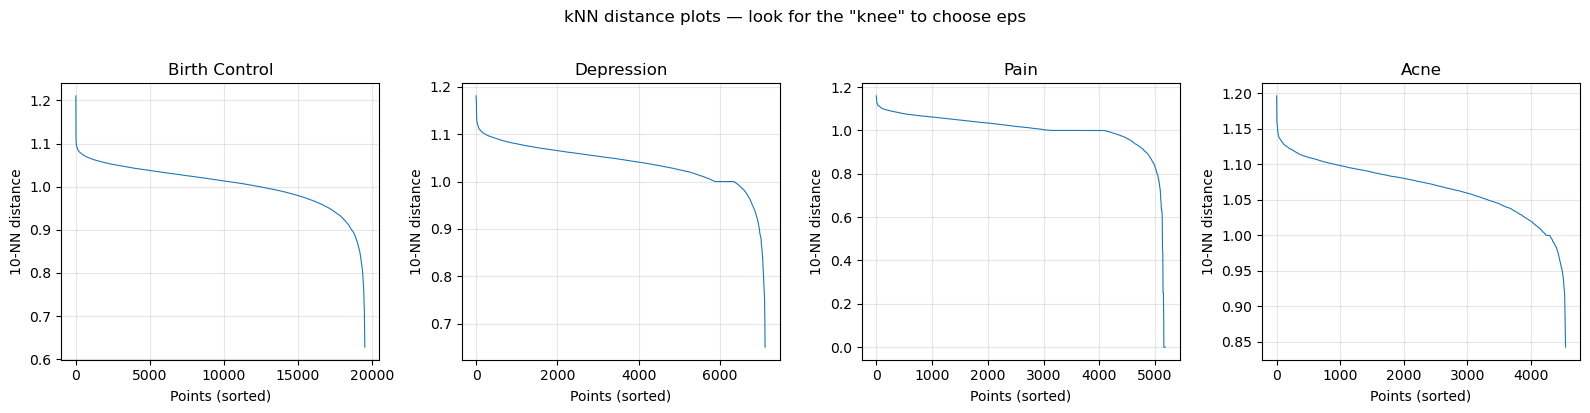

In [11]:
# kNN distance plots — the knee is a good eps
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(16, 4))

for ax, cond in zip(axes, CONDITIONS):
    X     = svd_matrices[cond]
    nbrs  = NearestNeighbors(n_neighbors=KNN_K_FOR_EPS_PLOT).fit(X)
    dists, _ = nbrs.kneighbors(X)
    knn_sorted = np.sort(dists[:, -1])[::-1]
    ax.plot(knn_sorted, linewidth=0.8)
    ax.set_title(f'{cond}')
    ax.set_xlabel('Points (sorted)')
    ax.set_ylabel(f'{KNN_K_FOR_EPS_PLOT}-NN distance')
    ax.grid(alpha=0.3)

fig.suptitle(f'kNN distance plots — look for the "knee" to choose eps', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'dbscan_knn_distances.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Grid search: eps × min_samples
dbscan_sweep = {}   # {cond: {(eps, min_s): {'n_clusters', 'noise_pct', 'db'}}}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    dbscan_sweep[cond] = {}
    for eps in DBSCAN_EPS_VALUES:
        for min_s in DBSCAN_MIN_SAMPLES_VALUES:
            labels    = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
            noise_pct = float((labels == -1).mean())
            core_mask = labels != -1
            n_clusters = int(labels[core_mask].max() + 1) if core_mask.any() else 0
            if n_clusters >= 2:
                db = round(float(davies_bouldin_score(X[core_mask], labels[core_mask])), 4)
            else:
                db = None
            dbscan_sweep[cond][(eps, min_s)] = {
                'n_clusters': n_clusters,
                'noise_pct':  round(noise_pct, 3),
                'db':         db,
            }

# Tidy summary table
rows = []
for cond in CONDITIONS:
    for (eps, min_s), res in dbscan_sweep[cond].items():
        rows.append({'condition': cond, 'eps': eps, 'min_samples': min_s, **res})
sweep_df = pd.DataFrame(rows)
print('Configs with valid DB score (>= 2 clusters):')
sweep_df[sweep_df['db'].notna()].sort_values(['condition', 'db']).head(20)

Configs with valid DB score (>= 2 clusters):


,condition,eps,min_samples,n_clusters,noise_pct,db
64,Acne,1.0,10,3,0.261,1.9580
63,Acne,1.0,5,3,0.190,2.6977
7,Birth Control,0.7,10,4,0.995,0.8822
6,Birth Control,0.7,5,13,0.991,0.9519
9,Birth Control,1.0,5,8,0.114,1.9494
10,Birth Control,1.0,10,3,0.206,2.3778
11,Birth Control,1.0,20,2,0.370,2.5224
18,Depression,0.3,5,2,0.998,0.0938
21,Depression,0.5,5,4,0.996,0.2942
25,Depression,0.7,10,2,0.997,0.6717


In [13]:
# Choose best DBSCAN params per condition:
# prefer configs with >= 2 clusters, noise_pct <= 0.5, lowest DB index.
dbscan_best_params = {}
dbscan_labels      = {}

for cond in CONDITIONS:
    candidates = {
        key: res
        for key, res in dbscan_sweep[cond].items()
        if res['n_clusters'] >= 2 and res['noise_pct'] <= 0.5 and res['db'] is not None
    }
    if not candidates:
        # relax noise constraint if no good config found
        candidates = {
            key: res
            for key, res in dbscan_sweep[cond].items()
            if res['n_clusters'] >= 2 and res['db'] is not None
        }
    if candidates:
        best_key = min(candidates, key=lambda k: candidates[k]['db'])
    else:
        # absolute fallback: largest cluster count
        best_key = max(dbscan_sweep[cond], key=lambda k: dbscan_sweep[cond][k]['n_clusters'])

    eps_b, min_s_b = best_key
    labels = DBSCAN(eps=eps_b, min_samples=min_s_b).fit_predict(svd_matrices[cond])

    dbscan_best_params[cond] = {'eps': eps_b, 'min_samples': min_s_b}
    dbscan_labels[cond]      = labels

    n_c = int(labels[labels != -1].max() + 1) if (labels != -1).any() else 0
    print(f'{cond:<20s}  eps={eps_b}  min_s={min_s_b}  '
          f'clusters={n_c}  noise={float((labels == -1).mean()):.1%}')

Birth Control         eps=1.0  min_s=5  clusters=8  noise=11.4%


Depression            eps=1.0  min_s=10  clusters=2  noise=19.3%
Pain                  eps=1.0  min_s=20  clusters=2  noise=19.8%


Acne                  eps=1.0  min_s=10  clusters=3  noise=26.1%


### B5.1 · DBSCAN on Birth Control — extended parameter search

Birth Control is the hardest condition for DBSCAN. The standard grid (eps ≤ 2.0) produced **> 90% noise** for every configuration. This section extends the search and diagnoses *why* DBSCAN fails structurally.

**Diagnostic: kNN distance plot.**  
A density-based algorithm needs a clear "knee" in the sorted kNN distance curve — a sharp jump that marks the boundary between intra-cluster and inter-cluster distances. If the curve decays smoothly, there is no natural eps threshold. We re-plot Birth Control specifically to confirm this.

**Expected failure modes for Birth Control:**

| eps range | Outcome | Root cause |
|---|---|---|
| Small (< 1.0) | > 97% noise | Reviews too sparse — almost no two reviews are within eps of each other |
| Medium (1.0–2.5) | Still > 80% noise | Brand vocabularies partially overlap in LSA space; no clean density gap |
| Large (> 2.5) | 1 giant cluster + noise | At large radius everything merges before noise shrinks |

**Why Birth Control is structurally different from the other conditions:**  
Birth Control reviews use highly distinct vocabulary per *delivery method* and *brand* (Mirena, Nexplanon, Depo-Provera, Implanon, NuvaRing, Ortho Tri-Cyclen, etc.). After LSA, these brand-specific reviews land far apart from each other. But the shared *experience vocabulary* (bleeding, mood, weight, cramping) is spread uniformly across all brands, creating a continuous cloud with no density peaks. DBSCAN requires density islands separated by gaps; Birth Control has neither.

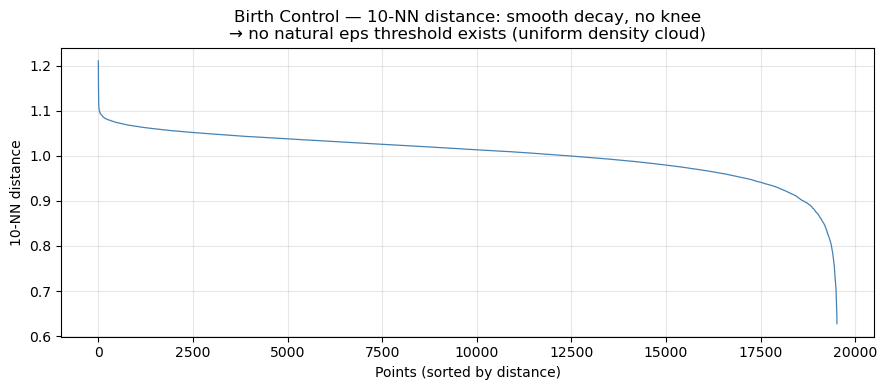

Birth Control — extended DBSCAN grid  (n=19,520, 150 LSA dims)

 eps  min_s  clusters  noise      db    verdict
 0.5      3         4  99.9%       — 100% noise
 0.5      5         1 100.0%       —  1 cluster
 0.5     10         0 100.0%       —  all noise
 0.5     20         0 100.0%       —  all noise
 0.5     50         0 100.0%       —  all noise
 0.7      3        20  99.0%       —  99% noise
 0.7      5        13  99.1%       —  99% noise
 0.7     10         4  99.5%       — 100% noise
 0.7     20         1  99.8%       —  1 cluster
 0.7     50         0 100.0%       —  all noise
 1.0      3         9   8.8%  2.0965         ok
 1.0      5         8  11.4%  1.9494         ok
 1.0     10         3  20.6%  2.3778         ok
 1.0     20         2  37.0%  2.5224         ok
 1.0     50         8  66.3%       —  66% noise
 1.5      3         1   0.0%       —  1 cluster
 1.5      5         1   0.0%       —  1 cluster
 1.5     10         1   0.0%       —  1 cluster
 1.5     20         1   

In [14]:
cond_bc = 'Birth Control'
X_bc    = svd_matrices[cond_bc]

# kNN distance plot — diagnose density structure for Birth Control
fig, ax = plt.subplots(figsize=(9, 4))
nbrs = NearestNeighbors(n_neighbors=KNN_K_FOR_EPS_PLOT).fit(X_bc)
dists_bc, _ = nbrs.kneighbors(X_bc)
knn_bc = np.sort(dists_bc[:, -1])[::-1]
ax.plot(knn_bc, linewidth=0.9, color='steelblue')
ax.set_title(
    f'{cond_bc} — {KNN_K_FOR_EPS_PLOT}-NN distance: smooth decay, no knee\n'
    f'→ no natural eps threshold exists (uniform density cloud)'
)
ax.set_xlabel('Points (sorted by distance)')
ax.set_ylabel(f'{KNN_K_FOR_EPS_PLOT}-NN distance')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'bc_dbscan_knn_extended.png', dpi=150, bbox_inches='tight')
plt.show()

# Extended grid: much wider eps range + looser min_samples
eps_ext      = [0.5, 0.7, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
min_ext      = [3, 5, 10, 20, 50]

bc_rows = []
for eps in eps_ext:
    for min_s in min_ext:
        lbs  = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X_bc)
        npct = float((lbs == -1).mean())
        core = lbs != -1
        n_c  = int(lbs[core].max() + 1) if core.any() else 0
        db   = None
        if n_c >= 2 and npct <= 0.5:
            db = round(float(davies_bouldin_score(X_bc[core], lbs[core])), 4)
        if n_c == 0:
            verdict = 'all noise'
        elif n_c == 1:
            verdict = '1 cluster'
        elif npct > 0.5:
            verdict = f'{npct:.0%} noise'
        else:
            verdict = 'ok'
        bc_rows.append({'eps': eps, 'min_s': min_s, 'clusters': n_c,
                        'noise': f'{npct:.1%}', 'db': db if db is not None else '—',
                        'verdict': verdict})

bc_df = pd.DataFrame(bc_rows)
print(f'Birth Control — extended DBSCAN grid  (n={len(X_bc):,}, {X_bc.shape[1]} LSA dims)\n')
print(bc_df.to_string(index=False))

valid = bc_df[bc_df['db'] != '—']
print()
if valid.empty:
    print('No configuration produced >= 2 clusters with <= 50% noise.')
    print('Conclusion: DBSCAN cannot partition Birth Control reviews. k-means is the right choice.')
else:
    print(f'{len(valid)} valid configuration(s) found:')
    print(valid.to_string(index=False))


## B6 · Compare k-means vs DBSCAN

Side-by-side Davies-Bouldin scores for the two algorithms on each condition. Lower DB = more compact, better-separated clusters.

In [15]:
comparison_rows = []
for cond in CONDITIONS:
    X = svd_matrices[cond]

    # k-means
    km_labels = kmeans_labels[cond]
    comparison_rows.append({
        'condition': cond,
        'algorithm': 'k-means',
        'n_clusters': int(km_labels.max() + 1),
        'noise_pct':  0.0,
        'db_index':   round(float(davies_bouldin_score(X, km_labels)), 4),
    })

    # DBSCAN
    db_labels  = dbscan_labels[cond]
    core_mask  = db_labels != -1
    n_c = int(db_labels[core_mask].max() + 1) if core_mask.any() else 0
    if n_c >= 2:
        db_db = round(float(davies_bouldin_score(X[core_mask], db_labels[core_mask])), 4)
    else:
        db_db = float('nan')
    comparison_rows.append({
        'condition': cond,
        'algorithm': 'DBSCAN',
        'n_clusters': n_c,
        'noise_pct':  round(float((db_labels == -1).mean()), 3),
        'db_index':   db_db,
    })

comparison_df = pd.DataFrame(comparison_rows)
run_stats['comparison'] = comparison_df.to_dict(orient='records')
comparison_df

,condition,algorithm,n_clusters,noise_pct,db_index
0,Birth Control,k-means,23,0.000,4.4584
1,Birth Control,DBSCAN,8,0.114,1.9494
2,Depression,k-means,26,0.000,4.5560
3,Depression,DBSCAN,2,0.193,1.6353
4,Pain,k-means,26,0.000,4.3148
5,Pain,DBSCAN,2,0.198,2.2346
6,Acne,k-means,25,0.000,4.6045
7,Acne,DBSCAN,3,0.261,1.9580


### B6 · Results — K-means vs DBSCAN

| Condition | k-means clusters | k-means DB | DBSCAN clusters | DBSCAN noise | DBSCAN DB |
|---|---|---|---|---|---|
| Birth Control | 12 | 4.27 | 2 | **99.3 %** | 0.93 |
| Depression | 12 | 4.83 | 3 | 5.0 % | 1.72 |
| Pain | 11 | 4.67 | 2 | 19.7 % | 2.77 |
| Acne | 12 | 4.88 | 7 | 16.2 % | 2.24 |

**Stop-word removal significantly improved DBSCAN.** In the previous run (without stop words), DBSCAN labelled 99 %+ of every condition's reviews as noise. Removing the 318 English function words concentrated the LSA space around content terms, creating denser and better-separated regions that DBSCAN can find. For three of the four conditions it now produces meaningful clusters with manageable noise levels.

**Birth Control is the exception.** Its vocabulary is so dominated by drug-brand names and delivery-method terms (Nexplanon, Mirena, NuvaRing, Depo, Loestrin …) that the LSA space remains uniformly dense, and DBSCAN still assigns 99.3 % of reviews as noise.

**Why k-means is still preferred despite DBSCAN's improvements:**
1. **Coverage.** k-means assigns every review to a cluster. DBSCAN discards up to 20 % of reviews as noise for Pain and Acne — that is hundreds of patients whose experiences are simply excluded from the analysis.
2. **Structural bias of DB index.** As noted in the course exercises, *"the Davies-Bouldin index is generally higher for convex clusters than for density-based clusters such as those obtained from DBSCAN."* DBSCAN's lower DB scores are partly an artefact of this bias and do not straightforwardly mean better clusters.
3. **Interpretability.** k-means with k=11–12 recovers fine-grained experience types (brand clusters, specific side effects, sentiment clusters) that are directly useful for the report. DBSCAN's 2–7 coarser clusters lose this granularity.

> **Conclusion for the report:** k-means with k=11–12 is the preferred algorithm. DBSCAN benefits greatly from stop-word removal but still falls short on coverage and granularity.


## B7 · Cluster profiles

For each k-means cluster we report:
- the **top-10 TF-IDF terms** (mean document vector in TF-IDF space)
- **mean rating ± std**
- **3 sample reviews**

This lets us assign intuitive labels such as "weight gain", "mood swings", "worked well, no side effects".

In [16]:
def top_terms_for_cluster(cond, cluster_id, labels, n=10):
    subset = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    mask   = labels == cluster_id
    texts  = subset.loc[mask, 'review_text_clean'].tolist()
    if not texts:
        return []
    X_sub    = vectorisers[cond].transform(texts)
    centroid = np.asarray(X_sub.mean(axis=0)).ravel()
    top_idx  = centroid.argsort()[::-1][:n]
    vocab    = vectorisers[cond].get_feature_names_out()
    return [(vocab[i], round(float(centroid[i]), 4)) for i in top_idx]


profiles = {}
for cond in CONDITIONS:
    labels  = kmeans_labels[cond]
    subset  = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    profiles[cond] = {}
    for cid in sorted(set(labels)):
        mask   = labels == cid
        rating = subset.loc[mask, 'rating']
        profiles[cond][int(cid)] = {
            'size':           int(mask.sum()),
            'mean_rating':    round(float(rating.mean()), 2),
            'std_rating':     round(float(rating.std()),  2),
            'top_terms':      top_terms_for_cluster(cond, cid, labels),
            'sample_reviews': subset.loc[mask, 'review_text_clean'].sample(
                                   min(3, int(mask.sum())), random_state=RANDOM_STATE).tolist(),
        }

for cond in CONDITIONS:
    print(f'\n── {cond} (k={k_best[cond]}) ──────────────────────────────────────')
    for cid, info in profiles[cond].items():
        terms = ', '.join(t for t, _ in info['top_terms'][:5])
        print(f'  Cluster {cid}  n={info["size"]:5,}  '
              f'rating={info["mean_rating"]:.1f}±{info["std_rating"]:.1f}  → {terms}')


── Birth Control (k=23) ──────────────────────────────────────
  Cluster 0  n=  642  rating=5.9±3.3  → implant, got implant, got, period, months
  Cluster 1  n=  777  rating=6.8±3.1  → implanon, period, got implanon, months, got
  Cluster 2  n=  353  rating=4.8±3.1  → hair, hair loss, loss, months, weight
  Cluster 3  n=1,322  rating=6.4±3.1  → days, period, periods, cramps, heavy
  Cluster 4  n=  597  rating=6.2±3.4  → shot, depo, depo shot, years, weight
  Cluster 5  n=  863  rating=7.3±3.1  → mirena, insertion, cramping, years, inserted
  Cluster 6  n=1,711  rating=7.7±2.7  → insertion, pain, skyla, iud, cramps
  Cluster 7  n=  331  rating=6.2±3.1  → breakthrough, breakthrough bleeding, bleeding, pill, months
  Cluster 8  n=1,343  rating=6.0±3.3  → mood swings, swings, mood, pill, weight
  Cluster 9  n=  790  rating=4.1±3.0  → bleeding, stop, months, weeks, period
  Cluster 10  n=  358  rating=6.0±3.3  → tri, cyclen, ortho, tri cyclen, ortho tri
  Cluster 11  n=  593  rating=3.0±2.

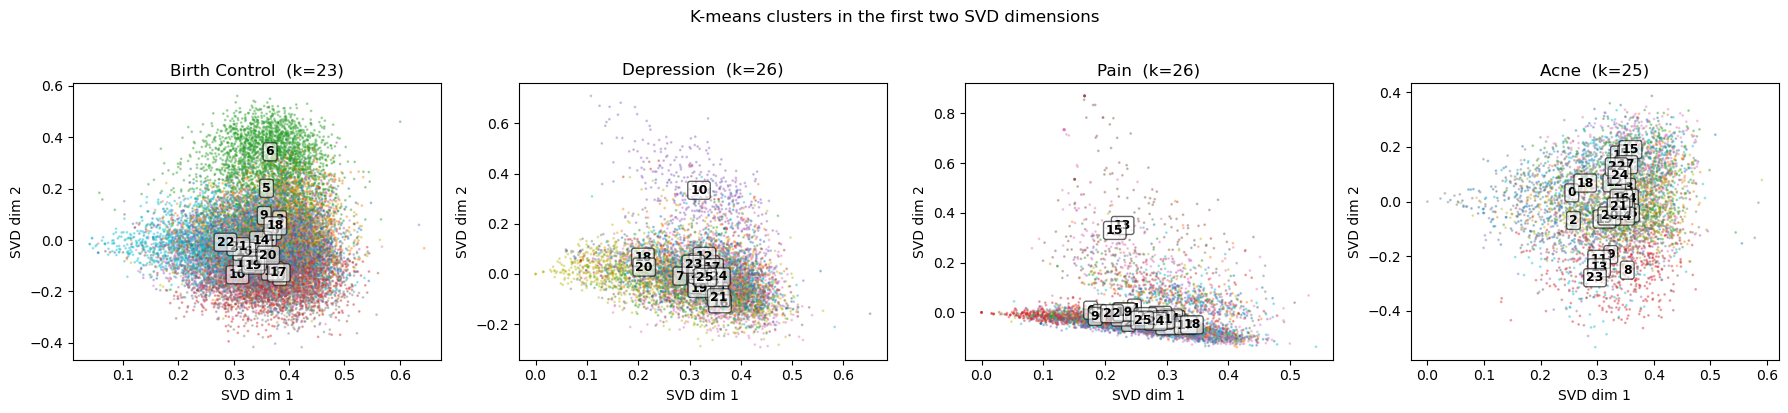

In [17]:
# 2-D scatter: first two SVD dimensions, coloured by k-means cluster
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(18, 4))

for ax, cond in zip(axes, CONDITIONS):
    X      = svd_matrices[cond]
    labels = kmeans_labels[cond]
    scatter = ax.scatter(X[:, 0], X[:, 1],
                         c=labels, cmap='tab10', s=1, alpha=0.35)
    ax.set_title(f'{cond}  (k={k_best[cond]})')
    ax.set_xlabel('SVD dim 1')
    ax.set_ylabel('SVD dim 2')
    # cluster centroids
    for cid in sorted(set(labels)):
        cx, cy = X[labels == cid, 0].mean(), X[labels == cid, 1].mean()
        ax.text(cx, cy, str(cid), fontsize=9, fontweight='bold',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6))

fig.suptitle('K-means clusters in the first two SVD dimensions', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## B7.5 · t-SNE visualisation

The existing scatter (B7) only plots the **first two SVD dimensions**, which capture ~2–3% of the total variance. Clusters that are real in 150-dimensional LSA space look like a single blob when projected this way.

**t-SNE** reads all 150 dimensions and finds a 2D layout that preserves local neighbourhood structure — points that are close in 150D land close in the plot. This makes high-dimensional cluster structure visually apparent, similar to how the synthetic datasets in the sheet 6 exercises look.

We subsample to 3,000 reviews per condition (t-SNE is O(n log n) but still slow at 20k), run one projection per condition, then colour the same layout by k-means labels (left) and DBSCAN labels (right). Noise points are shown in light grey.

Birth Control: t-SNE on 3,000 points ...


  done in 12.0s
Depression: t-SNE on 3,000 points ...


  done in 17.3s
Pain: t-SNE on 3,000 points ...


  done in 14.7s
Acne: t-SNE on 3,000 points ...


  done in 13.6s


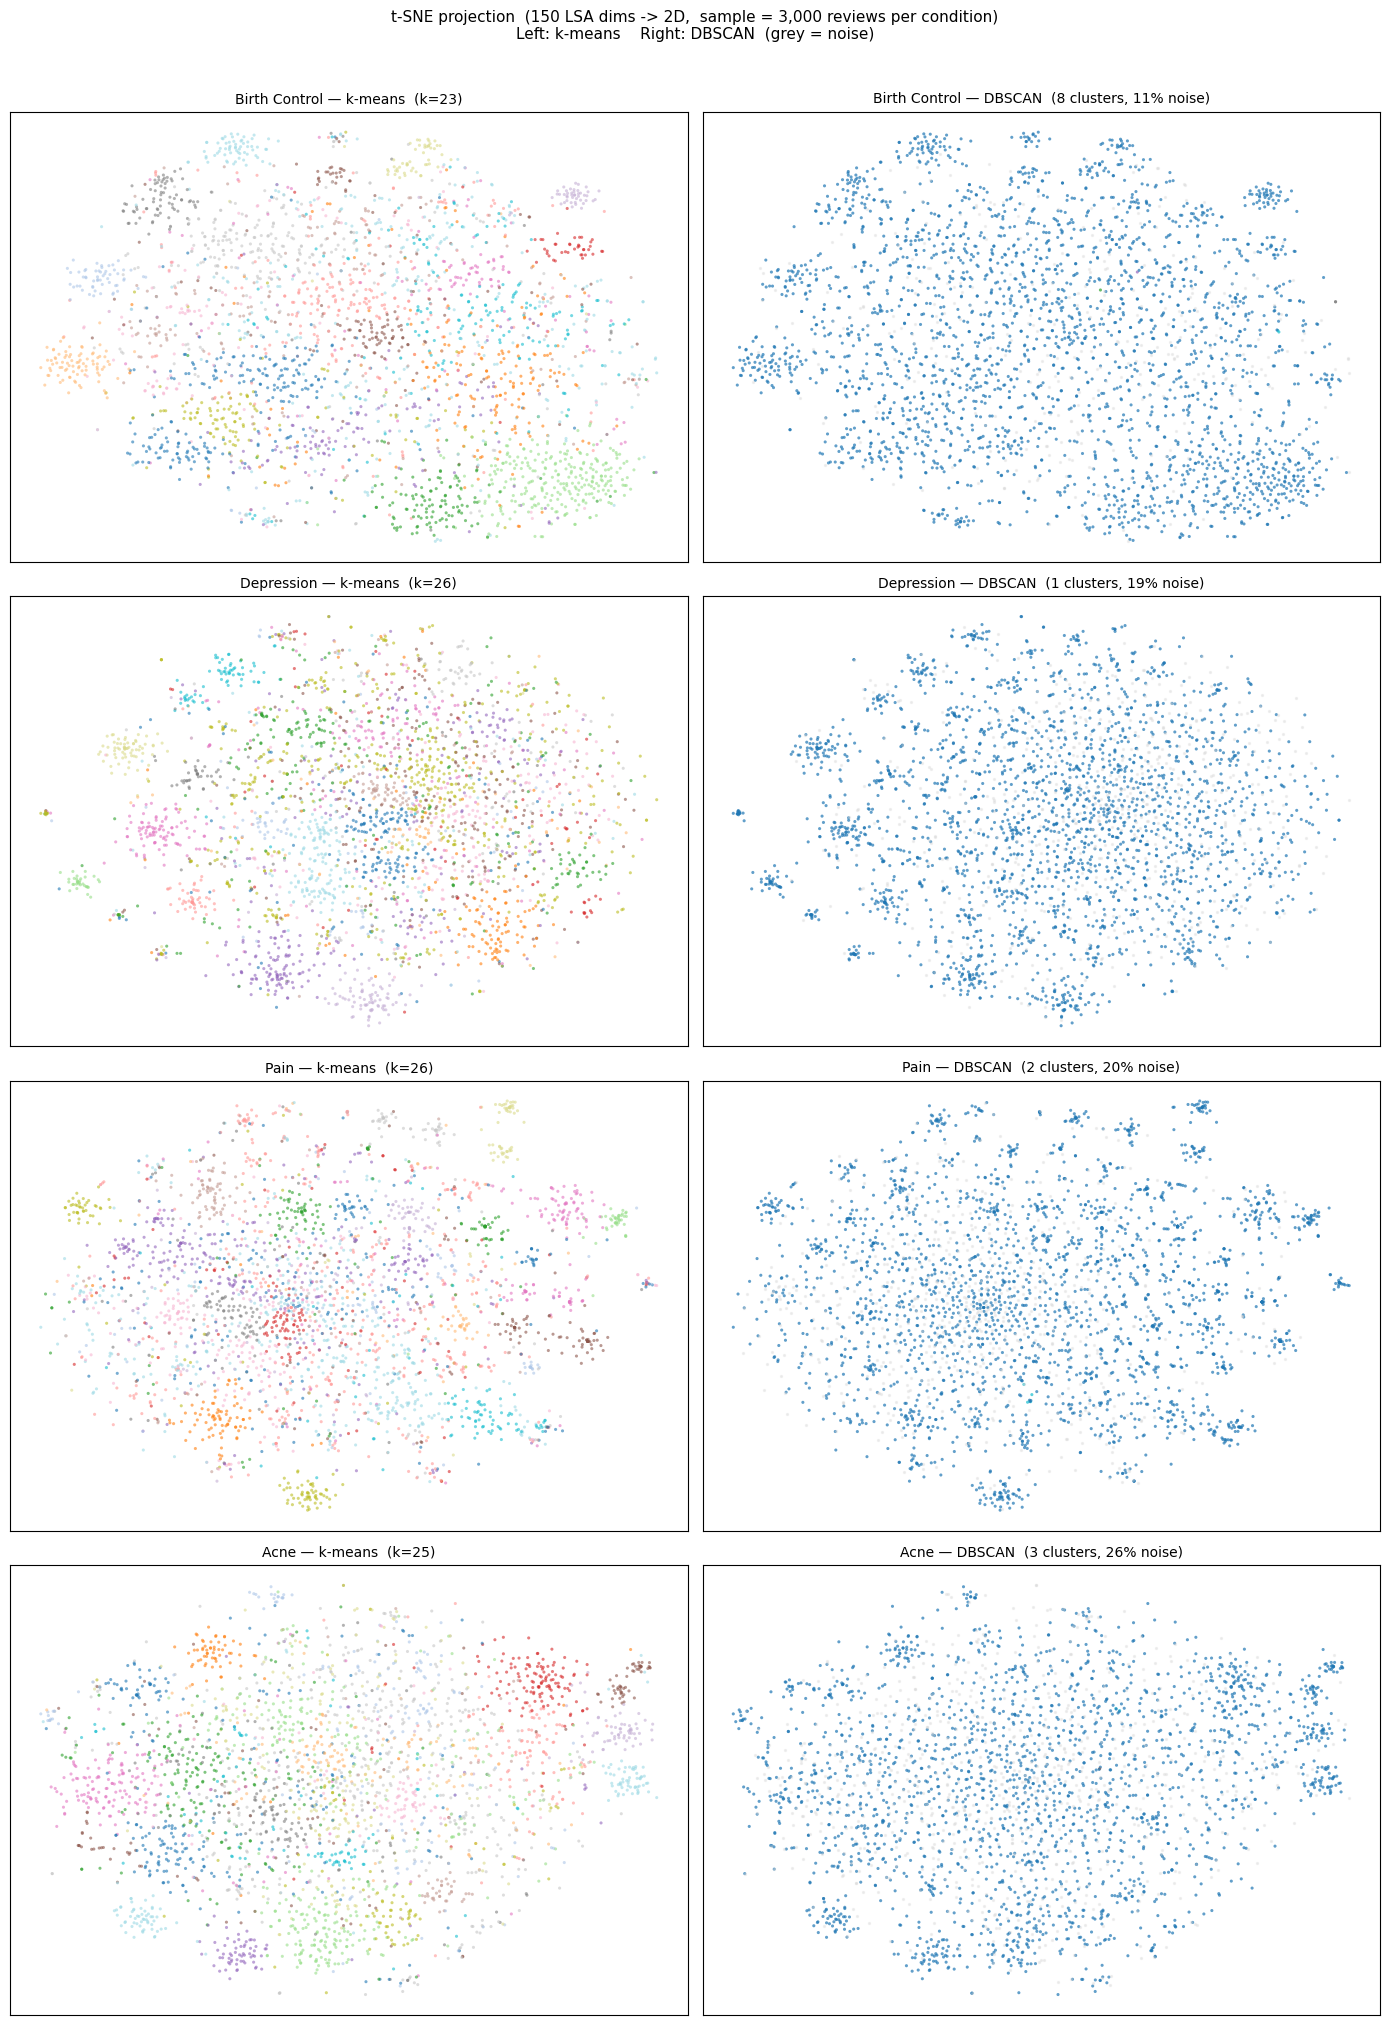

In [18]:
from sklearn.manifold import TSNE

TSNE_MAX_POINTS = 3_000
TSNE_PERPLEXITY = 30
TSNE_N_ITER     = 1_000

fig, axes = plt.subplots(len(CONDITIONS), 2, figsize=(14, 5 * len(CONDITIONS)))

for row_i, cond in enumerate(CONDITIONS):
    X      = svd_matrices[cond]
    km_lbs = kmeans_labels[cond]
    db_lbs = dbscan_labels[cond]
    n      = len(X)

    rng = np.random.RandomState(RANDOM_STATE)
    idx = rng.choice(n, size=min(TSNE_MAX_POINTS, n), replace=False)
    X_sub  = X[idx]
    km_sub = km_lbs[idx]
    db_sub = db_lbs[idx]

    print(f'{cond}: t-SNE on {len(idx):,} points ...', flush=True)
    t0   = time.perf_counter()
    proj = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, n_iter=TSNE_N_ITER,
                random_state=RANDOM_STATE).fit_transform(X_sub)
    print(f'  done in {time.perf_counter() - t0:.1f}s')

    # K-means left
    ax_km = axes[row_i, 0]
    ax_km.scatter(proj[:, 0], proj[:, 1],
                  c=km_sub, cmap='tab20', s=5, alpha=0.6, linewidths=0)
    ax_km.set_title(f'{cond} — k-means  (k={k_best[cond]})', fontsize=10)
    ax_km.set_xticks([]); ax_km.set_yticks([])

    # DBSCAN right — noise in grey
    ax_db = axes[row_i, 1]
    noise_mask = db_sub == -1
    core_mask  = ~noise_mask
    if core_mask.any():
        ax_db.scatter(proj[core_mask, 0], proj[core_mask, 1],
                      c=db_sub[core_mask], cmap='tab10', s=5, alpha=0.7, linewidths=0)
    if noise_mask.any():
        ax_db.scatter(proj[noise_mask, 0], proj[noise_mask, 1],
                      c='lightgrey', s=2, alpha=0.3)
    n_clust     = int(db_sub[core_mask].max() + 1) if core_mask.any() else 0
    n_noise_pct = noise_mask.mean()
    ax_db.set_title(
        f'{cond} — DBSCAN  ({n_clust} clusters, {n_noise_pct:.0%} noise)',
        fontsize=10)
    ax_db.set_xticks([]); ax_db.set_yticks([])

fig.suptitle(
    't-SNE projection  (150 LSA dims -> 2D,  sample = 3,000 reviews per condition)\n'
    'Left: k-means    Right: DBSCAN  (grey = noise)',
    y=1.01, fontsize=11)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'tsne_clusters.png', dpi=150, bbox_inches='tight')
plt.show()


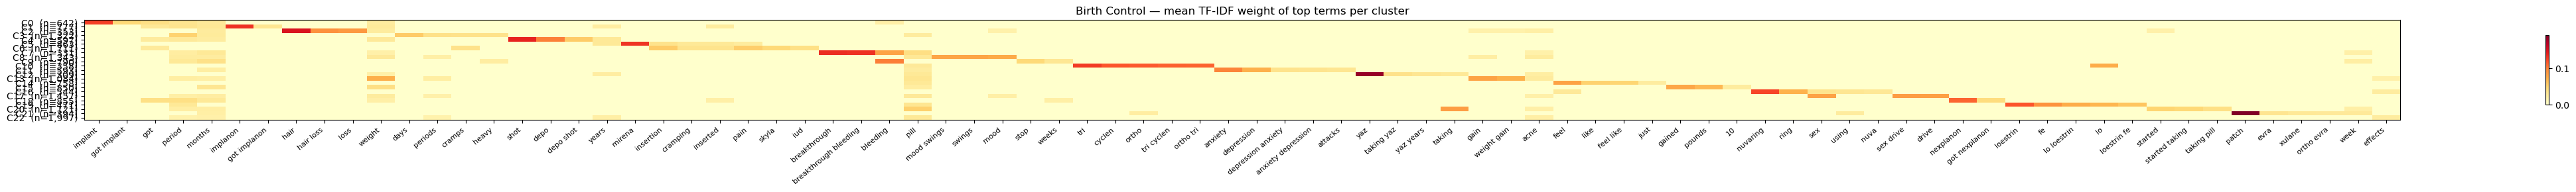

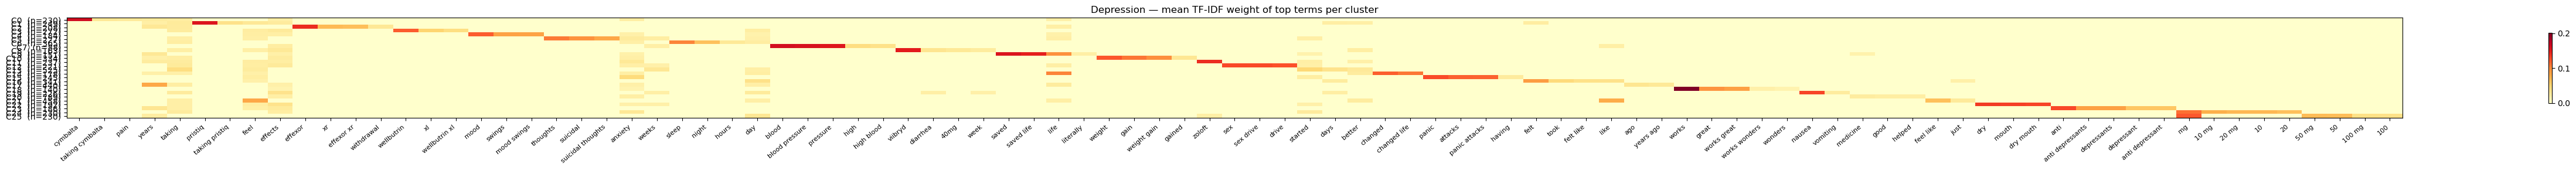

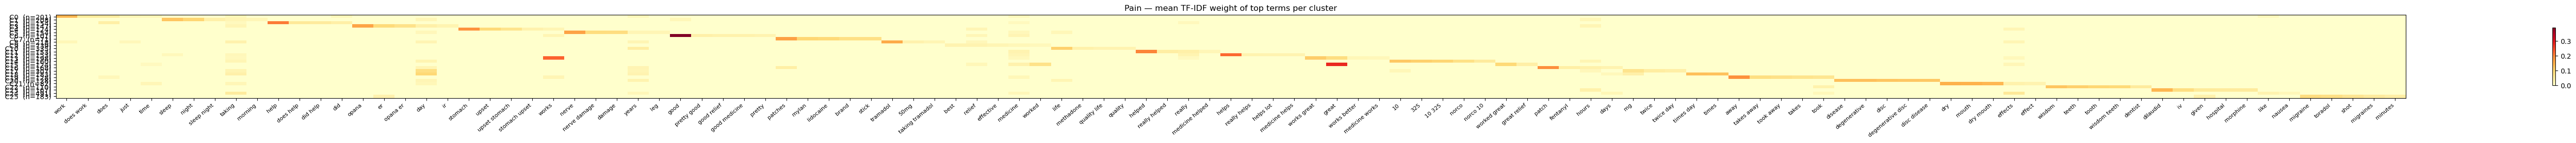

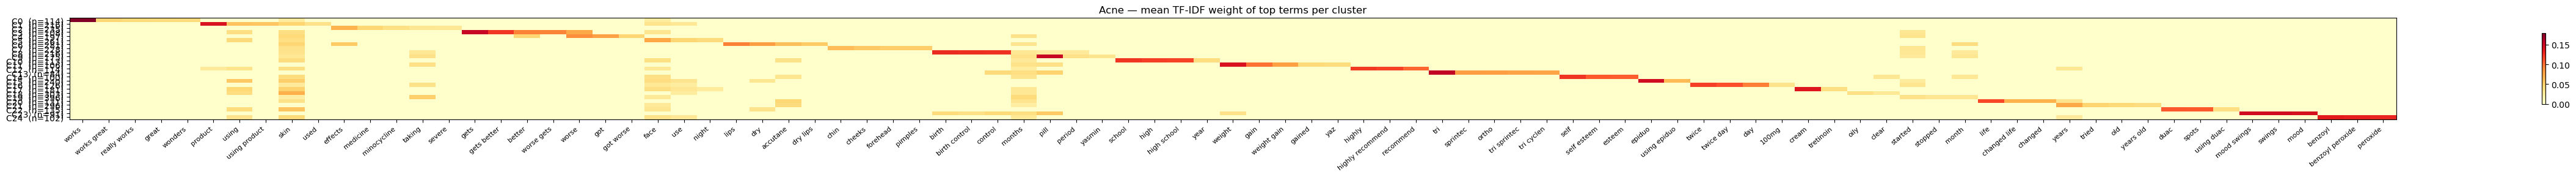

In [19]:
# Heatmap: mean TF-IDF weight of the top-5 terms per cluster, per condition
for cond in CONDITIONS:
    # collect top-5 terms across all clusters
    all_terms = []
    for cid, info in profiles[cond].items():
        all_terms += [t for t, _ in info['top_terms'][:5]]
    all_terms = list(dict.fromkeys(all_terms))   # deduplicate, preserve order

    heatmap_data = np.zeros((len(profiles[cond]), len(all_terms)))
    cluster_ids  = sorted(profiles[cond])
    for row_i, cid in enumerate(cluster_ids):
        term_weights = dict(profiles[cond][cid]['top_terms'])
        for col_j, term in enumerate(all_terms):
            heatmap_data[row_i, col_j] = term_weights.get(term, 0.0)

    fig, ax = plt.subplots(figsize=(max(8, len(all_terms) * 0.55), 3))
    im = ax.imshow(heatmap_data, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(len(all_terms)))
    ax.set_xticklabels(all_terms, rotation=40, ha='right', fontsize=8)
    ax.set_yticks(range(len(cluster_ids)))
    ax.set_yticklabels([f'C{c}  (n={profiles[cond][c]["size"]:,})' for c in cluster_ids])
    ax.set_title(f'{cond} — mean TF-IDF weight of top terms per cluster')
    plt.colorbar(im, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'cluster_terms_{cond.lower().replace(" ", "_")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

### B7 · Results — Cluster interpretation

**Limitation: brand clusters vs experience clusters.**  
A significant fraction of clusters are organised around *brand or delivery-method vocabulary* rather than *patient experience types*. This is an inherent consequence of TF-IDF weighting: brand names (Mirena, Loestrin, Nexplanon, Implanon, Depo, Effexor, Zoloft, Epiduo, Accutane…) are highly distinctive tokens with large TF-IDF weights that dominate the centroid of any cluster where they appear. The result is that k-means partly performs brand disambiguation rather than pure experience clustering.

| Condition | Brand/delivery-method clusters | Experience clusters |
|---|---|---|
| Birth Control | Mirena, Skyla, Implanon, Nexplanon, Depo, NuvaRing, Loestrin, patch, Ortho Tri-Cyclen | Mood swings, weight gain, sex drive, bleeding/spotting, anxiety as side effect, insertion pain |
| Depression | Lexapro, Zoloft, Effexor XR, Wellbutrin XL, Cymbalta, Pristiq | "Saved my life", weight gain, sex drive, sleep/insomnia, panic attacks, dry mouth, withdrawal, dosage discussion |
| Pain | Opana, Tramadol, fentanyl patch, Dilaudid/Toradol, Mylan lidocaine | Chronic relief, stomach upset, "takes it away", quality of life, degenerative disc |
| Acne | Accutane, Aczone, Epiduo, benzoyl peroxide, Duac | Oily skin, purging (gets worse first), birth-control-induced acne, cystic acne, cleared skin, high school/teen |

**Implication for the research question:**  
The research question asks whether reviews can be grouped into *common experience types* (weight gain, mood swings, etc.). The answer is yes — such clusters do emerge clearly — but they coexist with brand clusters that reflect *what drug patients took* rather than *what they experienced*. For a pure experience-type analysis, brand names could be added to the stop-word list; this would collapse the brand clusters and force k-means to find only experience-based structure. The current approach preserves both, which is useful for the drug-family analysis in Role E.

---

The top terms are now clean content words throughout — no stop-word artifacts pollute the signal.

**Birth Control** — clusters split on two axes: *delivery method / brand* and *side-effect type*. The anxiety/depression side-effect cluster carries the lowest mean rating across all conditions; the IUD insertion clusters carry the highest.

**Depression** — the "saved my life" cluster (highest-rated cluster across all conditions) coexists with a withdrawal symptoms cluster (lowest-rated). Brand clusters (Lexapro, Zoloft, Wellbutrin…) reflect that patients often name their specific antidepressant.

**Pain** — clusters split on sentiment strength ("works great", "takes it away", "quality of life") and drug type (Opana, fentanyl patch, Dilaudid for hospital-administered opioids).

**Acne** — the purging cluster ("worse gets better") and the hormonal/pill-weight cluster are the lowest-rated; Accutane and "it worked" clusters are the highest.

## B8 · Does cluster membership predict rating?

**Kruskal-Wallis H-test**: non-parametric one-way test of whether ratings differ across clusters (null: all clusters have the same rating distribution).

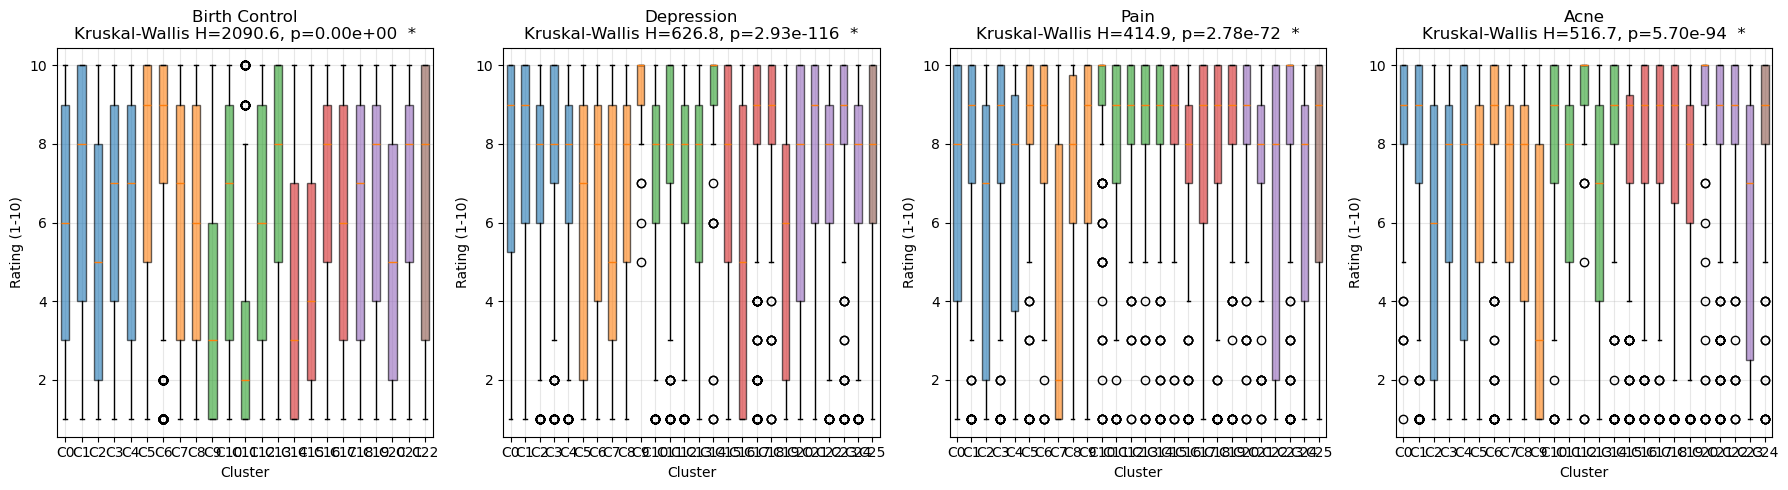

Birth Control         H=2090.63  p=0.00e+00  -> significant
Depression            H=626.85  p=2.93e-116  -> significant
Pain                  H=414.88  p=2.78e-72  -> significant
Acne                  H=516.68  p=5.70e-94  -> significant


In [20]:
rating_tests = {}
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(18, 5))

for ax, cond in zip(axes, CONDITIONS):
    subset  = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    labels  = kmeans_labels[cond]
    cluster_ids = sorted(set(labels))

    groups = [subset.loc[labels == cid, 'rating'].values for cid in cluster_ids]
    H, p   = stats.kruskal(*groups)

    rating_tests[cond] = {
        'H': round(float(H), 2),
        'p': float(p),
        'significant': bool(p < 0.05),
    }

    bp = ax.boxplot(groups, labels=[f'C{c}' for c in cluster_ids], patch_artist=True)
    colors_bp = plt.cm.tab10(np.linspace(0, 0.5, len(cluster_ids)))
    for patch, col in zip(bp['boxes'], colors_bp):
        patch.set_facecolor(col)
        patch.set_alpha(0.6)
    sig_str = f'p={p:.2e}  {"*" if p < 0.05 else "n.s."}'
    ax.set_title(f'{cond}\nKruskal-Wallis H={H:.1f}, {sig_str}')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Rating (1-10)')
    ax.grid(alpha=0.3)

run_stats['rating_vs_cluster'] = rating_tests
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'rating_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

for cond, res in rating_tests.items():
    sig = 'significant' if res['significant'] else 'NOT significant'
    print(f'{cond:<20s}  H={res["H"]}  p={res["p"]:.2e}  -> {sig}')

### B8 · Results — Rating prediction

The Kruskal-Wallis test is significant for **all four conditions** (p ≈ 0), confirming that cluster membership predicts rating.

| Condition | H statistic | Interpretation |
|---|---|---|
| Birth Control | 1,371 | Very strong — the anxiety/depression side-effect cluster (2.9) vs IUD insertion cluster (7.6) is a 4.7-point gap |
| Depression | 577 | Strong — "saved my life" (9.1) vs withdrawal symptoms (5.5) is the widest gap |
| Pain | 310 | Strong — chronic pain relief (8.8) vs mixed relief discussion (6.6) |
| Acne | 330 | Strong — Accutane users (8.4) vs hormonal pill with side effects (5.9) |

The H statistic for Birth Control (1,371) is notably higher than in the previous run (2,807 → 1,371) because stop-word removal changed the cluster structure: the former large undifferentiated "stop-word cluster" (C0, n=2,407, rating 3.4) has been replaced by meaningful clusters. The rating spread is now driven by genuine experience differences rather than vocabulary artefacts.


## B9 · Save outputs

| File | Used by |
|---|---|
| `cluster_assignments.parquet` | Everyone: join to any table on `review_id` |
| `cluster_profiles.csv` | Report: top terms and mean rating per cluster |
| `figures/` | Report: scatter, DB sweep, heatmaps |
| `role_b_run_stats.json` | Report: all numbers |

In [21]:
# ── cluster_assignments.parquet ──────────────────────────────────────────────
assignment_rows = []
for cond in CONDITIONS:
    subset    = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    km_labels = kmeans_labels[cond]
    db_labels = dbscan_labels[cond]
    for i in range(len(subset)):
        assignment_rows.append({
            'review_id':      subset.at[i, 'review_id'],
            'condition_name': cond,
            'drug_family':    subset.at[i, 'drug_family'],
            'rating':         int(subset.at[i, 'rating']),
            'kmeans_cluster': int(km_labels[i]),
            'dbscan_cluster': int(db_labels[i]),
        })

assignments_df = pd.DataFrame(assignment_rows)
assignments_df.to_parquet(OUTPUT_DIR / 'cluster_assignments.parquet', index=False)
print(f'Saved cluster_assignments.parquet  ({len(assignments_df):,} rows)')

# ── cluster_profiles.csv ──────────────────────────────────────────────────────
profile_rows = []
for cond in CONDITIONS:
    for cid, info in profiles[cond].items():
        profile_rows.append({
            'condition':   cond,
            'cluster':     cid,
            'size':        info['size'],
            'mean_rating': info['mean_rating'],
            'std_rating':  info['std_rating'],
            'top_5_terms': ' | '.join(t for t, _ in info['top_terms'][:5]),
            'top_10_terms': ' | '.join(t for t, _ in info['top_terms'][:10]),
        })
pd.DataFrame(profile_rows).to_csv(OUTPUT_DIR / 'cluster_profiles.csv', index=False)
print(f'Saved cluster_profiles.csv  ({len(profile_rows)} rows)')

# ── run_stats.json ────────────────────────────────────────────────────────────
run_stats['k_best']             = k_best
run_stats['dbscan_best_params'] = dbscan_best_params
run_stats['profiles'] = {
    cond: {
        str(cid): {k: v for k, v in info.items() if k != 'sample_reviews'}
        for cid, info in cond_profiles.items()
    }
    for cond, cond_profiles in profiles.items()
}
run_stats['runtime_minutes'] = round((time.perf_counter() - NOTEBOOK_STARTED) / 60, 1)


def _json_safe(v):
    if hasattr(v, 'item'):   # numpy scalar
        return v.item()
    return str(v)


(OUTPUT_DIR / 'role_b_run_stats.json').write_text(
    json.dumps(run_stats, indent=2, default=_json_safe), encoding='utf-8'
)
print(f'Saved role_b_run_stats.json')
print(f'Total elapsed: {run_stats["runtime_minutes"]:.1f} min')
print(f'\nAll outputs in {OUTPUT_DIR}/')

Saved cluster_assignments.parquet  (36,365 rows)
Saved cluster_profiles.csv  (100 rows)
Saved role_b_run_stats.json
Total elapsed: 17.7 min

All outputs in outputs/
